# 探索谱学数据集

本教程探索清洗后的实验数据集：有多少分子与谱图、有哪些核种、峰位置如何分布，以及如何划分训练数据。图中的分布来自完整清洗数据的直方图。

## 读取数据摘要

摘要保存 H/C 分子数量，以及各实验视图的谱数量。选择任务所需数据集之前，先查看这些字段。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, SVG
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir())
sys.path.insert(0, str(root / 'scripts'))
summary = json.loads((root / 'documentation/assets/cleaned-data-summary.json').read_text())
print('H/C molecules:', summary['nmr']['molecular_identities'])
print('H spectra:', summary['nmr']['counts']['h_spectra'])
print('C spectra:', summary['nmr']['counts']['c_spectra'])
for modality, view in summary['experimental']['views'].items():
    print(modality, view['spectra'], 'spectra;', view['molecules'], 'molecules')

H/C molecules: 2678511
H spectra: 2720828
C spectra: 252015
IR 177759 spectra; 168197 molecules
19F 56679 spectra; 50402 molecules
31P 21662 spectra; 18238 molecules
MS 5233 spectra; 4980 molecules
11B 1140 spectra; 1017 molecules
Raman 42 spectra; 39 molecules
29Si 726 spectra; 636 molecules


## 分子大小与化学位移

重原子数与分子量描述训练数据覆盖的化学空间。NMR 面板展示解析后的 H/C 峰位置，单位为 ppm。尾部格汇总显示区间之外的值，因此图中保留了全部清洗记录。

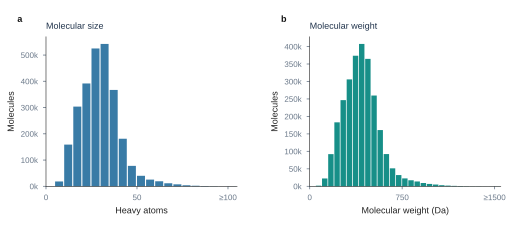

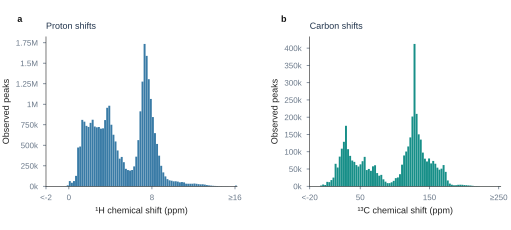

In [2]:
from build_manual_examples import distributions
import matplotlib.pyplot as plt
figures = distributions()
def show(name):
    stream = io.StringIO()
    figures[name].savefig(stream, format='svg', metadata={'Date': None})
    display(SVG(stream.getvalue()))
show('data-cleaned-nmr')
show('data-cleaned-nmr-shifts')

## 谱型覆盖与峰分布

核种数量图使用对数轴，以便同时展示高丰度和较少的核种。MS 面板展示分子大小与 m/z 峰位置，IR/Raman 面板使用 cm⁻¹ 波数。这些分布可用于选择通道掩码、输入网格和抽样策略。

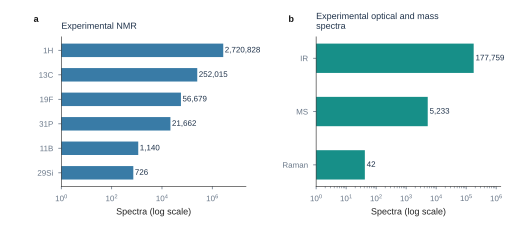

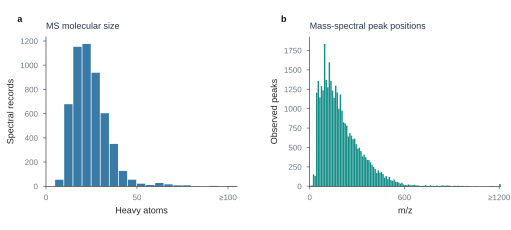

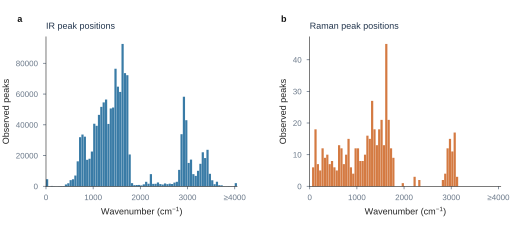

In [3]:
for name in ['data-cleaned-experimental', 'data-cleaned-ms', 'data-cleaned-vibrational']:
    show(name)
for figure in figures.values():
    plt.close(figure)

## 训练、验证和测试文件

清洗后的 H/C 集合保留训练、验证和测试文件。摘要记录各文件的分子数量和标准身份交集。使用训练集拟合，在验证集选择模型设置。

In [4]:
for role, view in summary['nmr']['files'].items():
    print(role, view['records'], 'molecules')
print('Cross-split identity intersections:', summary['nmr']['split_identity_overlaps'])

train 2172790 molecules
val 250836 molecules
test 254885 molecules
Cross-split identity intersections: {'train/val': 0, 'train/test': 0, 'val/test': 0}


[Data guide](../data/index.md) · [Dataset API](../api-reference/module-datasets.md) · [Create a split](../data/splits.md)